# Glioma survival analysis — Step 3: proper evaluation

Step 2 measured the C-index on the same data the model was trained on → optimistic.
Here:

1. **Hold-out test set** (20%, fixed seed) — locked away, used **once** at the end.
2. **Repeated 5-fold CV** (5×3 = 15 folds) on the training set to compare models.
3. **Metrics** (all in `src/survival_utils.py`, reused in Steps 4–5):
   * Harrell's C and **Uno's C** (IPCW, robust to heavy censoring, truncated at 36 m)
   * **time-dependent AUC** at 6 / 12 / 24 / 36 months
   * **Integrated Brier Score (IBS)** — lower is better
4. **Missing values** are no longer dropped: imputation happens *inside* each fold (no leakage), so all 1040 patients are used.

In [1]:
import sys
sys.path.insert(0, "../src")
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sksurv.linear_model import CoxPHSurvivalAnalysis
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test

from survival_utils import (load_data, split, make_preprocessor, LifelinesCox, KaplanMeierBaseline,
                            cross_validate, evaluate, summarize, survival_at, EVAL_TIMES)

X, y = load_data("../data/processed/glioma.csv")
X_train, X_test, y_train, y_test = split(X, y)
print(f"train: {len(X_train)} ({y_train['event'].mean():.0%} deaths)   test: {len(X_test)} ({y_test['event'].mean():.0%} deaths)")

train: 832 (50% deaths)   test: 208 (50% deaths)


## 1. Candidate models
Nested feature sets answer: *how much does each block of information add?*

| model | features |
|---|---|
| KM baseline | none |
| Cox – age | age |
| Cox – clinical | age, sex, grade, KPS |
| Cox – molecular | age, subtype (IDH/1p19q), MGMT, chr7+/10− |
| Cox – full | all of the above |
| Cox – full, stratified | all, but each subtype gets its own baseline hazard (fixes the PH violation from Step 2) |

A small ridge penalty (`alpha` / `penalizer`) keeps the coefficients stable when a category is rare in a fold.

In [2]:
def cox(numeric, categorical, alpha=0.1):
    return make_pipeline(make_preprocessor(numeric, categorical), CoxPHSurvivalAnalysis(alpha=alpha))

models = {
    "KM baseline":        KaplanMeierBaseline(),
    "Cox – age":          cox(["age"], []),
    "Cox – clinical":     cox(["age", "grade", "kps"], ["sex"]),
    "Cox – molecular":    cox(["age"], ["subtype", "mgmt", "chr7_10"]),
    "Cox – full":         cox(["age", "grade", "kps"], ["sex", "subtype", "mgmt", "chr7_10"]),
    "Cox – full, strat.": make_pipeline(make_preprocessor(), LifelinesCox(penalizer=0.01, strata_prefix="subtype_")),
}

## 2. Repeated cross-validation (training set only)

In [3]:
cv_results = {name: cross_validate(m, X_train, y_train) for name, m in models.items()}

table = summarize(cv_results)
table[["harrell_c", "uno_c", "auc_6m", "auc_12m", "auc_24m", "auc_36m", "mean_auc", "ibs"]]

,harrell_c,uno_c,auc_6m,auc_12m,auc_24m,auc_36m,mean_auc,ibs
KM baseline,0.5 ± 0.0,0.5 ± 0.0,0.5 ± 0.0,0.5 ± 0.0,0.5 ± 0.0,0.5 ± 0.0,0.5 ± 0.0,0.218 ± 0.011
Cox – age,0.735 ± 0.03,0.725 ± 0.029,0.794 ± 0.051,0.773 ± 0.055,0.8 ± 0.05,0.823 ± 0.038,0.796 ± 0.037,0.166 ± 0.013
Cox – clinical,0.789 ± 0.027,0.788 ± 0.025,0.831 ± 0.041,0.818 ± 0.043,0.858 ± 0.041,0.901 ± 0.026,0.852 ± 0.029,0.139 ± 0.014
Cox – molecular,0.775 ± 0.027,0.778 ± 0.024,0.797 ± 0.046,0.811 ± 0.046,0.861 ± 0.048,0.89 ± 0.042,0.841 ± 0.033,0.139 ± 0.014
Cox – full,0.793 ± 0.027,0.795 ± 0.026,0.825 ± 0.04,0.824 ± 0.039,0.872 ± 0.044,0.914 ± 0.03,0.859 ± 0.031,0.134 ± 0.015
"Cox – full, strat.",0.786 ± 0.024,0.783 ± 0.024,0.832 ± 0.037,0.815 ± 0.037,0.855 ± 0.042,0.899 ± 0.028,0.849 ± 0.028,0.133 ± 0.016


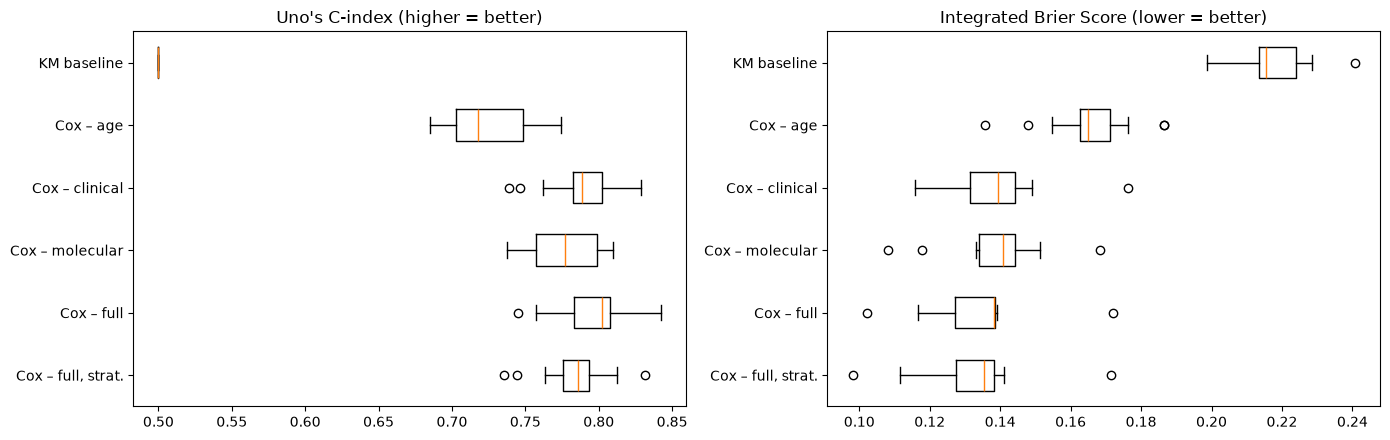

In [4]:
long = pd.concat([r.assign(model=n) for n, r in cv_results.items()])
long.to_csv("../results/cv_step3.csv", index=False)   # Steps 4-5 will append to this comparison

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
names = list(cv_results)
for a, metric, title in [(ax[0], "uno_c", "Uno's C-index (higher = better)"),
                         (ax[1], "ibs", "Integrated Brier Score (lower = better)")]:
    a.boxplot([cv_results[n][metric] for n in names], vert=False, tick_labels=names)
    a.set_title(title); a.invert_yaxis()
plt.tight_layout()

**How to read it**

* The jump from *age only* to *molecular* shows how much IDH / 1p19q add beyond age.
* *clinical* vs *full*: whether molecular markers still help once grade & KPS are known.
* Differences smaller than the fold-to-fold std are **not** meaningful — prefer the simpler model then.

## 3. Does stratification fix the proportional-hazards problem?
Step 2 flagged `age` and `IDHmut-non-codel`. With strata on subtype, subtype no longer needs a constant HR.

In [5]:
strat = models["Cox – full, strat."]
strat.fit(X_train, y_train)
Xt = strat[0].transform(X_train).assign(time=y_train["time"], event=y_train["event"].astype(int))
strat[-1].cph_.check_assumptions(Xt, p_value_threshold=0.05, show_plots=False, advice=False)



1. Variable 'age' failed the non-proportional test: p-value is 0.0046.


2. Variable 'missingindicator_kps' failed the non-proportional test: p-value is 0.0001.


3. Variable 'chr7_10_yes' failed the non-proportional test: p-value is 0.0349.



[]

In [6]:
strat[-1].cph_.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(3)

,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,
age,1.625,1.425,1.852,0.000
kps,0.814,0.735,0.901,0.000
grade,1.731,1.420,2.110,0.000
missingindicator_kps,1.108,0.999,1.229,0.053
sex_Male,1.099,0.896,1.347,0.365
mgmt_Methylated,0.888,0.694,1.137,0.347
mgmt_missing,0.922,0.713,1.192,0.535
chr7_10_missing,0.695,0.373,1.292,0.250
chr7_10_yes,0.921,0.728,1.164,0.489


## 4. Final check on the hold-out test set
The model with the best mean Uno's C in CV is refit on the **whole training set** and evaluated on the test set — once.

In [7]:
cv_mean = {n: r["uno_c"].mean() for n, r in cv_results.items()}
best_name = max(cv_mean, key=cv_mean.get)
print("selected:", best_name)

test_rows = {}
for name in ["KM baseline", "Cox – age", best_name]:
    m = models[name].fit(X_train, y_train)
    test_rows[name] = evaluate(m, y_train, X_test, y_test)
test_table = pd.DataFrame(test_rows).T.round(3)
test_table.to_csv("../results/test_step3.csv")
test_table

selected: Cox – full


,harrell_c,uno_c,auc_6m,auc_12m,auc_24m,auc_36m,mean_auc,ibs
KM baseline,0.500,0.500,0.500,0.500,0.500,0.500,0.500,0.220
Cox – age,0.764,0.753,0.789,0.820,0.825,0.817,0.813,0.156
Cox – full,0.812,0.813,0.833,0.848,0.916,0.909,0.877,0.118


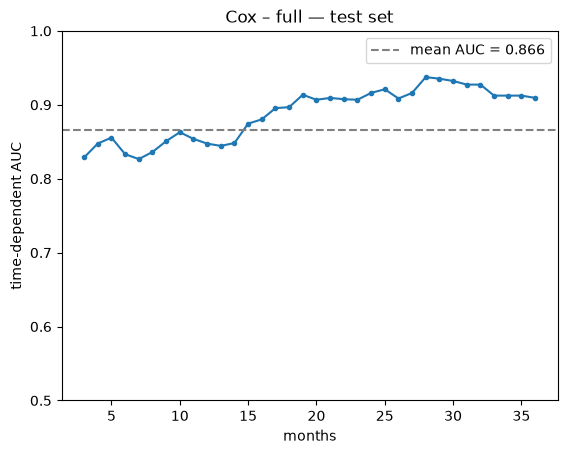

In [8]:
best = models[best_name].fit(X_train, y_train)
risk_test = best.predict(X_test)

from sksurv.metrics import cumulative_dynamic_auc
grid = np.arange(3, 37, 1)
auc, mean_auc = cumulative_dynamic_auc(y_train, y_test, risk_test, grid)
plt.plot(grid, auc, marker=".")
plt.axhline(mean_auc, ls="--", c="gray", label=f"mean AUC = {mean_auc:.3f}")
plt.ylim(0.5, 1); plt.xlabel("months"); plt.ylabel("time-dependent AUC")
plt.title(f"{best_name} — test set"); plt.legend();

### Risk groups on the test set
Cut-offs (tertiles) come from the **training** risk scores, then applied to test patients.
If the model generalizes, the three KM curves should separate clearly.

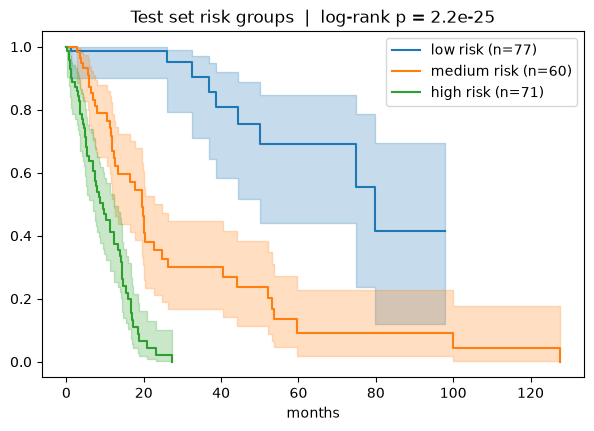

In [9]:
cuts = np.quantile(best.predict(X_train), [1/3, 2/3])
group = pd.Series(np.digitize(risk_test, cuts), index=X_test.index).map({0: "low", 1: "medium", 2: "high"})

fig, ax = plt.subplots(figsize=(7, 4.5))
for g in ["low", "medium", "high"]:
    mask = (group == g).to_numpy()
    KaplanMeierFitter().fit(y_test["time"][mask], y_test["event"][mask], label=f"{g} risk (n={mask.sum()})") \
        .plot_survival_function(ax=ax)
p = multivariate_logrank_test(y_test["time"], group, y_test["event"]).p_value
ax.set_title(f"Test set risk groups  |  log-rank p = {p:.1e}"); ax.set_xlabel("months");

### Calibration at 12 and 24 months
Patients are binned into quintiles of predicted survival; for each bin the predicted S(t) is compared
with the observed KM estimate. Points on the diagonal = well calibrated.

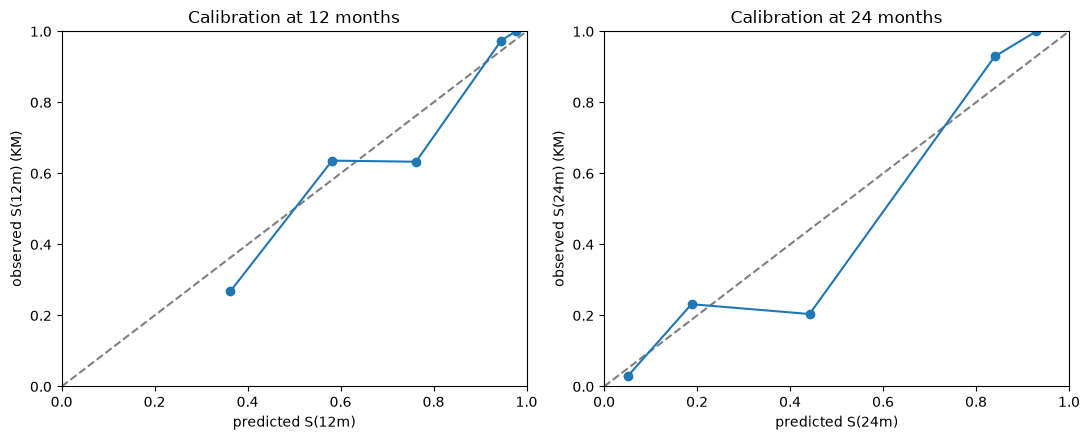

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, t in zip(axes, [12, 24]):
    pred = survival_at(best, X_test, np.array([t]))[:, 0]
    bins = pd.qcut(pred, 5, labels=False, duplicates="drop")
    obs, prd = [], []
    for b in np.unique(bins):
        m = bins == b
        km = KaplanMeierFitter().fit(y_test["time"][m], y_test["event"][m])
        obs.append(float(km.survival_function_at_times(t).iloc[0])); prd.append(pred[m].mean())
    ax.plot([0, 1], [0, 1], "--", c="gray")
    ax.plot(prd, obs, "o-")
    ax.set(xlabel=f"predicted S({t}m)", ylabel=f"observed S({t}m) (KM)", title=f"Calibration at {t} months",
           xlim=(0, 1), ylim=(0, 1))
plt.tight_layout()

## Summary

**CV (training set, 15 folds, mean ± std):**

| model | Uno's C | mean AUC | IBS |
|---|---|---|---|
| KM baseline | 0.500 | 0.500 | 0.218 |
| Cox – age | 0.725 ± 0.029 | 0.796 | 0.166 |
| Cox – molecular | 0.778 ± 0.024 | 0.841 | 0.139 |
| Cox – clinical | 0.788 ± 0.025 | 0.852 | 0.139 |
| **Cox – full** | **0.795 ± 0.026** | **0.859** | 0.134 |
| Cox – full, strat. | 0.783 ± 0.024 | 0.849 | 0.133 |

**Hold-out test (Cox – full):** Uno's C = 0.813, mean AUC = 0.877, IBS = 0.118 (KM baseline 0.220).

Takeaways
* The honest C-index (~0.79–0.81) is a bit below Step 2's training value (0.834), as expected.
* Age alone is already strong (0.73). Clinical (grade + KPS) and molecular (IDH/1p19q) blocks each add
  ~0.05–0.06, and they overlap a lot: combining them adds only ~0.01 → grade and IDH carry similar information.
* Clinical vs. full vs. stratified differ by less than one std → statistically indistinguishable.
* Stratifying on subtype removed the subtype PH violation, but `age`, `missingindicator_kps` and `chr7_10_yes`
  still violate PH → a hint of **non-linear / time-varying effects**, which is exactly what tree models (Step 4) can capture.
* Test risk groups separate very clearly (log-rank p ≈ 1e-25); calibration at 12 m is good, at 24 m roughly OK
  (small bins of ~40 patients → noisy).

**Benchmark for Step 4:** Random Survival Forest / Gradient Boosting must beat Uno's C ≈ 0.795 and IBS ≈ 0.134 in the same CV.